# Figure 3: Bound Summary

Translation of `Figure03_boundSummary.m`

## What this notebook does

Characterizes how participants' decision bounds vary with Decision Time (DT) and across trials in the online (OL) task.

Five panels (all using block 2, lowest SNR):

- **Panel A**: Individual trial bounds vs. DT for one example participant.
- **Panel B**: Z-scored bound vs. DT for all 60 participants (shows group-level DT dependence).
- **Panel C**: Histogram of linear-regression slopes (bound ~ DT) per participant.
- **Panel D**: Histogram of trial-to-trial bound change slopes (Δbound ~ previous bound) per participant.
- **Panel E**: Median [IQR] bound height vs. Median [IQR] DT per participant (x and y errorbars).

**Data**: Online (OL) task, block 2, lowest SNR condition.

## Imports

Imports standard scientific Python libraries plus `get_data_table` and `get_bound_summary` from the pigeon package. No data loading or filtering here.

## Load data

Loads all OL (online) trials via `get_data_table(task_type='OL')`. Internal processing:
- Reads all CSV files from `DATA_DIR/Pigeon_OL/prolificcsvs/`
- Computes `bound`, `DT`, `RT` for each trial from step sequences
- Marks wall-hit trials (|position| ≥ 0.75) in the `wall_hit` column
- Applies bias correction if `boundBiasCorrection.mat` is present
- Relabels blocks 4–6 as blocks 1–3 (`block_index` only — the physical blocks 1–3
  are the low-SNR condition, SNR≈0.33, and 4–6 are the high-SNR condition, SNR≈1.0,
  for the same three underlying block designs). This does **not** merge low- and
  high-SNR trials together: `snr` is untouched, so relabeled block 4/5/6 trials are
  still distinguishable from true block 1/2/3 trials by their SNR value. The next
  two cells rely on this — every downstream filter selects on `block_index`
  *and* `snr` together, which is what keeps "block 2" meaning "low-SNR block 2"
  rather than "low+high-SNR pooled". Verified directly against the raw
  (pre-relabel) block numbers: with the filters used below, 100% of selected
  trials originate from the true block 2, 0% from block 5.

All subjects and blocks retained at this stage.

## Compute bound summary

Calls `get_bound_summary(data_table_ol)` which applies the following filters internally (via `get_good_trial_array`):

**Data included**: Trials with `DT ≥ 2`, `trial_number ≥ 10`, `bound` finite and non-zero, `correct ≥ 0`, `wall_hit = False`, and `rt_below_cutoff = False` (RT meets the per-block/SNR reliability threshold from `get_bounds`).

**Data excluded**: Trials with `DT < 2` (too short), first 9 trials per block (warm-up), wall-hit trials, trials with missing bounds.

Output shape: `(n_subjects, n_blocks, n_snrs, n_rt_bins, 3)` where the last dimension is `[mean_abs_bound, std_abs_bound, n_trials]`.

## Select analysis parameters

Restricts analysis to block 2 (`BLOCK=2`) and the lowest SNR condition (`min_snr`).
Constructs the boolean filter `lg` used in all downstream panels.

**Data included**: Trials where `bound` is finite, `|SNR| ≈ min_snr`,
`block_index == BLOCK`, `DT ≥ 2`, `trial_number ≥ 10`, and `wall_hit = False` —
matching the filters applied internally by `get_bound_summary`. Using the same
filters ensures that the per-trial panels (A–E) draw from the same population as
the bound-summary statistics.

**Why both `block_index == BLOCK` and the SNR filter matter here**: after the
blocks 4–6 → 1–3 relabeling described above, `block_index == 2` alone would match
trials from *both* the true block 2 (low SNR) and the true block 5 (high SNR,
relabeled to 2). Requiring `|SNR| ≈ min_snr` in the same mask excludes the
relabeled high-SNR trials, so `lg` is restricted to the true low-SNR block 2 only
(confirmed directly against the raw, pre-relabel block numbers).

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats

from pigeon.data import get_data_table
from pigeon.stats import get_bound_summary
from pigeon.pathDefaults import FIGURES_DIR

In [2]:
data_table_ol = get_data_table(task_type='OL')

  1: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_14h39.24.096.csv
  2: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_15h37.48.260.csv
  3: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h34.46.761.csv
  4: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h35.25.285.csv
  5: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.33.669.csv
  6: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.41.364.csv
  7: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.49.086.csv
  8: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 14: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h35.53.048.csv
 15: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h48.56.013.csv
 16: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_19h38.38.956.csv
 17: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.04.663.csv
 18: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.05.544.csv
 19: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.07.852.csv
 20: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h37.13.084.csv
 21: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 28: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h40.06.581.csv
 29: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h41.15.620.csv
 30: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h42.16.563.csv
 31: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h46.46.975.csv
 32: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h54.23.759.csv
 33: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h30.52.958.csv
 34: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h34.58.360.csv
 35: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 43: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h39.13.059.csv
 44: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h41.40.441.csv
 45: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h42.52.039.csv
 46: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h42.54.723.csv
 47: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h49.12.728.csv
 48: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_01h07.36.399.csv
 49: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_01h09.54.461.csv
 50: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 56: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h38.28.207.csv
 57: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h39.12.114.csv
 58: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.02.817.csv
 59: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.07.382.csv
 60: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h41.01.524.csv


In [3]:
# bound_summary shape: (n_subjects, n_blocks, n_snrs, n_rt_bins, 3)
# Last dim: [mean_abs_bound, std_abs_bound, n_trials]
bound_summary = get_bound_summary(data_table_ol)
print('bound_summary shape:', bound_summary.shape)

bound_summary shape: (60, 3, 2, 10, 3)


In [4]:
BLOCK = 2  # representative block (1-indexed)

n_subjects, n_blocks, n_snrs, n_rt_bins, _ = bound_summary.shape

# Unique absolute SNR values present in the dataset
abs_snr = np.abs(data_table_ol['snr'].to_numpy())
snrs = np.sort(np.unique(abs_snr[np.isfinite(abs_snr)]))
min_snr = snrs[0]

# Quality filter applied to raw data_table_ol — matches get_good_trial_array criteria
# used internally by get_bound_summary so all panels draw from the same trial set.
lg = (
    data_table_ol['bound'].notna() &
    pd.Series(np.isclose(abs_snr, min_snr), index=data_table_ol.index) &
    (data_table_ol['block_index'] == BLOCK) &
    (data_table_ol['DT'] >= 2) &
    (data_table_ol['trial_number'] >= 10) &
    (data_table_ol['wall_hit'] == False)
)

subjects = np.sort(data_table_ol['subject_index'].dropna().unique())

## Compute per-panel statistics

Computes all inputs needed for the five figure panels and prints key statistics.

- **Panel A**: Example session — mean |bound| per DT bin for subject `EXAMPLE_SESSION`.
- **Panel B**: Z-scored bound vs. DT per subject; Spearman correlation of the group mean with DT.
- **Panel C**: Linear-regression slope of |bound| ~ DT per subject (DT ≥ 2); Wilcoxon test vs. 0.
- **Panel D**: Linear-regression slope of Δ|bound| ~ previous |bound| per subject; Wilcoxon tests vs. −1 (regression to mean) and vs. 0.
- **Panel E**: Per-subject median [IQR] of |bound| and DT; Spearman correlation between them.
  Uses the median (not mean) because per-trial DT is heavy-tailed (some subjects have
  individual trials with DT up to ~40-48 steps), which makes the mean — and any
  mean ± SEM error bar — highly sensitive to a handful of long trials. The median is
  far more robust to that tail (matches the convention used for DT in Figure02's
  accuracy-vs-DT panel).

In [5]:
EXAMPLE_SESSION = 16
dt_vals = np.arange(1, n_rt_bins + 1)

# Panel A: example session bounds vs DT — median (not mean) per DT bin, matching
# the median-based convention used throughout this notebook (robust to the
# heavy-tailed per-trial DT distribution).
ls_ex = lg & (data_table_ol['subject_index'] == EXAMPLE_SESSION)
ex = data_table_ol[ls_ex].copy()
ex_median_per_dt = np.array([np.nanmedian(np.abs(ex.loc[ex['DT'] == dt, 'bound']))
                              for dt in dt_vals])
ex_n_per_dt       = np.array([ex['DT'].eq(dt).sum() for dt in dt_vals])

# Panel B: z-scored bound vs DT for all subjects
subj_means = np.full((len(subjects), n_rt_bins), np.nan)
for si, subj in enumerate(subjects):
    ls  = lg & (data_table_ol['subject_index'] == subj)
    sub = data_table_ol[ls].copy()
    if len(sub) < 5:
        continue
    ab = np.abs(sub['bound'].to_numpy(dtype=float))
    mu, sd = np.nanmean(ab), np.nanstd(ab)
    if sd == 0:
        continue
    z = (ab - mu) / sd
    for ri, dt in enumerate(dt_vals):
        vals = z[sub['DT'].to_numpy() == dt]
        if len(vals) > 0:
            subj_means[si, ri] = np.nanmean(vals)
group_mean = np.nanmean(subj_means, axis=0)
valid_gm   = np.isfinite(group_mean)
r_b, p_b   = scipy.stats.spearmanr(dt_vals[valid_gm], group_mean[valid_gm])
print(f'Panel B: group mean z-bound Spearman r = {r_b:.2f}, p = {p_b:.4f}')

# Panel C: |bound| vs DT regression slopes (lg already ensures DT >= 2)
slopes_c = []
for subj in subjects:
    ls  = lg & (data_table_ol['subject_index'] == subj)
    sub = data_table_ol[ls]
    if len(sub) < 5:
        continue
    dts = sub['DT'].to_numpy(dtype=float)
    ab  = np.abs(sub['bound'].to_numpy(dtype=float))
    ok  = np.isfinite(dts) & np.isfinite(ab)
    if ok.sum() < 3:
        continue
    slope, *_ = scipy.stats.linregress(dts[ok], ab[ok])
    slopes_c.append(slope)
slopes_c = np.array(slopes_c)
med_c    = np.nanmedian(slopes_c)
bins_c   = np.arange(-0.04, 0.04 + 0.008, 0.008)
_, p_c   = scipy.stats.wilcoxon(slopes_c)
print(f'Panel C: median slope = {med_c:.4f}, Wilcoxon p = {p_c:.4f}')

# Panel D: Δbound vs previous bound regression slopes
# Regressing against the PREVIOUS trial's |bound| (not the current one) is what
# makes slope = -1 correspond to classical regression to the mean.
slopes_d = []
for subj in subjects:
    ls  = lg & (data_table_ol['subject_index'] == subj)
    sub = data_table_ol[ls].sort_values('trial_number')
    if len(sub) < 5:
        continue
    ab    = np.abs(sub['bound'].to_numpy(dtype=float))
    prev  = ab[:-1]
    delta = ab[1:] - prev
    ok    = np.isfinite(prev) & np.isfinite(delta)
    if ok.sum() < 3:
        continue
    slope, *_ = scipy.stats.linregress(prev[ok], delta[ok])
    slopes_d.append(slope)
slopes_d  = np.array(slopes_d)
med_d     = np.nanmedian(slopes_d)
bins_d    = np.arange(-2, 0 + 0.15, 0.15)
_, p_d_m1 = scipy.stats.wilcoxon(slopes_d + 1)
_, p_d_0  = scipy.stats.wilcoxon(slopes_d)
print(f'Panel D: median slope = {med_d:.4f}, Wilcoxon vs -1 p = {p_d_m1:.4f}, vs 0 p = {p_d_0:.4f}')

# Panel E: median [IQR] bound and DT per subject.
# Median (not mean) because per-trial DT is heavy-tailed (see markdown above) —
# mean +/- SEM pulls several subjects' points far off to the right (mean DT up
# to ~18), whereas the median stays close to the bulk of the data.
median_bound = np.full(len(subjects), np.nan)
bound_q25    = np.full(len(subjects), np.nan)
bound_q75    = np.full(len(subjects), np.nan)
median_dt    = np.full(len(subjects), np.nan)
dt_q25       = np.full(len(subjects), np.nan)
dt_q75       = np.full(len(subjects), np.nan)
for si, subj in enumerate(subjects):
    ls  = lg & (data_table_ol['subject_index'] == subj)
    sub = data_table_ol[ls]
    if len(sub) < 5:
        continue
    ab  = np.abs(sub['bound'].to_numpy(dtype=float))
    dts = sub['DT'].to_numpy(dtype=float)
    median_bound[si] = np.nanmedian(ab)
    bound_q25[si], bound_q75[si] = np.nanpercentile(ab, [25, 75])
    median_dt[si]    = np.nanmedian(dts)
    dt_q25[si], dt_q75[si] = np.nanpercentile(dts, [25, 75])
valid  = np.isfinite(median_bound) & np.isfinite(median_dt)
r_e, p_e = scipy.stats.spearmanr(median_dt[valid], median_bound[valid])
print(f'Panel E: median bound vs median DT Spearman r = {r_e:.2f}, p = {p_e:.4f}')
print(f'Panel E: group median bound = {np.nanmedian(median_bound[valid]):.3f}, '
      f'group median DT = {np.nanmedian(median_dt[valid]):.2f}')

Panel B: group mean z-bound Spearman r = -0.23, p = 0.5457
Panel C: median slope = -0.0025, Wilcoxon p = 0.0437
Panel D: median slope = -0.9688, Wilcoxon vs -1 p = 0.0506, vs 0 p = 0.0000
Panel E: median bound vs median DT Spearman r = 0.91, p = 0.0000
Panel E: group median bound = 0.322, group median DT = 6.00


/Users/jigold/miniconda3/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/var/folders/tp/dghl0fxd0wg0rsyq4p4tzcnc0000gn/T/ipykernel_56528/2861091155.py:29: RuntimeWarning: Mean of empty slice
  group_mean = np.nanmean(subj_means, axis=0)


## Figure

Publication layout matching MATLAB's `getPLOT_axes` call:

```matlab
getPLOT_axes(3, 8.5, [4,4,2,4], {1,1,2,1}, 1.3, 1.5, [], 'Pigeons', true)
```

- **Width**: 8.5 cm; **Row heights**: [4, 4, 2, 4] cm; vertical separation 1.3 cm; horizontal 1.5 cm
- Panels A, B, E span the full width; panels C and D share row 3 as equal halves
- **Font size**: 12 pt
- Saves to `Figure03.pdf`.

/var/folders/tp/dghl0fxd0wg0rsyq4p4tzcnc0000gn/T/ipykernel_56528/3485899151.py:61: RuntimeWarning: Mean of empty slice
  ax_B.plot(dt_vals, np.nanmean(subj_means, axis=0), 'r-', linewidth=2)


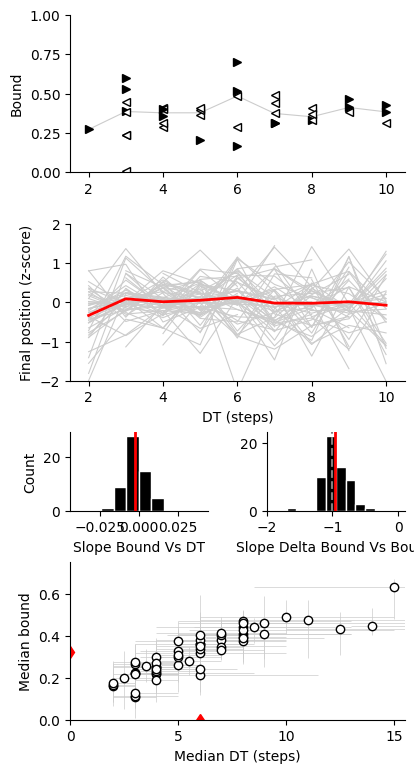

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03.pdf
Panel E x-limit: (0, 15.5) — max median DT = 15.0


In [6]:
import matplotlib.gridspec as gridspec

CM  = 1 / 2.54
WID = 8.5
HTS = [4.0, 4.0, 2.0, 4.0]
PSH = 1.3
PSW = 1.5
FS  = 12

fig_h       = sum(HTS) + PSH * (len(HTS) - 1)
panel_w     = (WID - PSW) / 2
hspace_frac = PSH / np.mean(HTS)
wspace_frac = PSW / panel_w

fig = plt.figure(figsize=(WID * CM, fig_h * CM))
gs = gridspec.GridSpec(4, 2, figure=fig,
                       height_ratios=HTS,
                       hspace=hspace_frac, wspace=wspace_frac,
                       left=0, right=1, bottom=0, top=1)

ax_A = fig.add_subplot(gs[0, :])
ax_B = fig.add_subplot(gs[1, :])
ax_C = fig.add_subplot(gs[2, 0])
ax_D = fig.add_subplot(gs[2, 1])
ax_E = fig.add_subplot(gs[3, :])

plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS})

gr = (0.8, 0.8, 0.8)

# Panels A, B share the same DT x-scale. The good-trial filter requires DT >= 2,
# so the per-trial data span DT = 2..10; 1.5-10.5 centers that range with equal
# margin on both sides instead of clipping the DT=10 points at the axis edge.
DT_XLIM = (1.5, 10.5)

# Panel A: Example session — individual bounds vs. DT. Choice side is shown via
# marker shape/fill, same convention as Figure02 panel A: filled right-pointing
# triangle = right choice, open left-pointing triangle = left choice.
# The per-DT median for this one example participant is thin gray — the same
# style as an individual participant's trace in panel B below (this line *is*
# literally one of panel B's per-subject traces, just not z-scored). Red is
# reserved for actual across-participant summary statistics, which this panel
# doesn't have (it's a single example subject).
ax_A.plot(dt_vals[ex_n_per_dt > 0], ex_median_per_dt[ex_n_per_dt > 0],
          color=gr, linewidth=0.8)
for _, row in ex.iterrows():
    x, y = row['DT'], abs(row['bound'])
    if row['choice'] == 1:
        ax_A.plot(x, y, marker='>', color='k', markerfacecolor='k', markersize=6)
    else:
        ax_A.plot(x, y, marker='<', color='k', markerfacecolor='w', markersize=6)
ax_A.set_xlim(*DT_XLIM)
ax_A.set_ylim(0, 1)
ax_A.set_ylabel('Bound')

# Panel B: Z-scored bound vs. DT — all subjects. Individual per-subject traces
# are thin gray — the same style as panel A's single-subject line above, since
# both represent one participant's DT-binned bound trajectory. The bold red
# line is the actual group mean, the only true summary statistic in this panel.
ax_B.plot(dt_vals, subj_means.T, '-', color=gr, linewidth=0.8)
ax_B.plot(dt_vals, np.nanmean(subj_means, axis=0), 'r-', linewidth=2)
ax_B.set_xlim(*DT_XLIM)
ax_B.set_ylim(-2, 2)
ax_B.set_xlabel('DT (steps)')
ax_B.set_ylabel('Final position (z-score)')

# Panel C: Histogram of bound-vs-DT regression slopes. Median line is solid red
# (not dotted) — dotted/dashed is reserved for theoretical reference values
# (e.g. panel D's slope=-1 line), solid red is the observed-median convention.
ax_C.hist(slopes_c, bins=bins_c, color='k', edgecolor='w')
ax_C.axvline(med_c, color='r', linewidth=2, linestyle='-')
ax_C.set_xlabel('Slope Bound Vs DT')
ax_C.set_ylabel('Count')

# Panel D: Histogram of delta-bound-vs-bound slopes
# Reference line at slope = -1 marks perfect regression to the mean (the null
# hypothesis tested by the Wilcoxon-vs--1 test above; dashed gray = theoretical
# reference). The observed median (solid red) is compared against it.
ax_D.hist(slopes_d, bins=bins_d, color='k', edgecolor='w')
ax_D.axvline(med_d, color='r', linewidth=2, linestyle='-')
ax_D.axvline(-1, color='gray', linewidth=1.5, linestyle='--')
d_ticks = sorted(set(ax_D.get_xticks().tolist()) | {-1.0})
ax_D.set_xticks(d_ticks)
ax_D.set_xlim(bins_d[0], bins_d[-1])
ax_D.set_xlabel('Slope Delta Bound Vs Bound')

# Panel E: median [IQR] bound vs. median [IQR] DT per subject.
# Median/IQR (not mean/SEM) because per-trial DT is heavy-tailed — a handful of
# subjects have individual trials with DT up to ~40-48 steps, which would pull
# their mean DT (and error bar) far outside a reasonable axis range.
# x-limit is set from the data (ceil of the max per-subject median DT, +0.5
# margin), matching Figure02's accuracy-vs-median-DT panel, so every subject's
# point is visible rather than clipped or pushed off-frame. Symbol/errorbar
# styling (marker size, gray errorbar color, capsize, linewidth), and the red
# diamond margin markers for the group medians, match Figure02's panel 3
# convention.
ax_E.errorbar(
    median_dt[valid], median_bound[valid],
    xerr=[median_dt[valid] - dt_q25[valid], dt_q75[valid] - median_dt[valid]],
    yerr=[median_bound[valid] - bound_q25[valid], bound_q75[valid] - median_bound[valid]],
    fmt='ko', markerfacecolor='w',
    ecolor=gr, capsize=0, linewidth=0.5, zorder=2)
ax_E.plot(0, np.nanmedian(median_bound[valid]), 'rd', markerfacecolor='r')
ax_E.plot(np.nanmedian(median_dt[valid]), 0, 'rd', markerfacecolor='r')
dt_xlim_hi_e = np.ceil(np.nanmax(median_dt[valid])) + 0.5
ax_E.set_xlim(0, dt_xlim_hi_e)
ax_E.set_ylim(0, 0.75)
ax_E.set_xlabel('Median DT (steps)')
ax_E.set_ylabel('Median bound')

for ax in [ax_A, ax_B, ax_C, ax_D, ax_E]:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

out = FIGURES_DIR / 'Figure03.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out}')
print(f'Panel E x-limit: (0, {dt_xlim_hi_e}) — max median DT = {np.nanmax(median_dt[valid]):.1f}')